# **Exercise 3 – Regularisation and Generalisation**
*Group 74 : AI-ML Assessment 1*

**Introduction**

In this exercise, we study how different regularisation techniques affect the generalisation performance of a CNN trained on the CIFAR-10 dataset.

The experiment focuses on two methods: dropout and data augmentation. The two methods are analysed separately in order to measure the effect of each on overfitting.

The baseline CNN from Exercise 2 serves as the benchmark network. Its architecture and training configuration are kept unchanged for a fair comparison.

**Experimental Design**

The CNN developed in Exercise 2 is the starting point for comparison. It has two convolutional layers with 32 and 64 channels, followed by a fully connected output layer of 10 neurons.

*   Baseline: the original CNN without dropout or data augmentation.
*   Dropout: the baseline CNN with a dropout layer (p = 0.3) added before the classifier.
*   Data augmentation: the baseline CNN trained on augmented training images, with the architecture unchanged.

For every model, the checkpoint with the highest validation accuracy is selected and then evaluated once on the test set.

---

# Reusing the baseline preparation

# 1.Imports

In [1]:
import sys, time, random, hashlib
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import copy


import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.datasets as datasets
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset

# group settings
SEED        = 42
BATCH_SIZE  = 128
EPOCHS      = 20
LEARNING_RATE = 1e-3
WEIGHT_DECAY  = 0.0
VAL_SIZE    = 5000            # from train set only
NUM_WORKERS = 0
DATA_DIR    = "./data"

CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD  = (0.2470, 0.2435, 0.2616)

CLASS_NAMES = ["aeroplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Python {sys.version.split()[0]} | PyTorch {torch.__version__} | torchvision {torchvision.__version__}")
print(f"Device: {device}")

Python 3.13.16 | PyTorch 2.14.1+cu130 | torchvision 0.29.1+cu130
Device: cuda


In [2]:
import platform

def cpu_name():
    try:
        with open("/proc/cpuinfo") as f:
            for line in f:
                if "model name" in line:
                    return line.split(":")[1].strip()
    except OSError:
        pass
    return platform.processor() or platform.machine()

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", device)
print("CPU:", cpu_name())
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.13.16
PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
Device: cuda
CPU: Intel(R) Xeon(R) CPU @ 2.00GHz
GPU: Tesla T4


# 2.Random seed setup

In [3]:
def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)
print(f"Seed set to {SEED}")

Seed set to 42


# 3.CIFAR-10 Dataset Preparation and Train/Validation Split

In [4]:
# No augmentation
base_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD)
])

train_transform = base_transform
eval_transform = base_transform

full_train_for_train = datasets.CIFAR10(
    DATA_DIR,
    train=True,
    download=True,
    transform=train_transform
)

full_train_for_val = datasets.CIFAR10(
    DATA_DIR,
    train=True,
    download=True,
    transform=eval_transform
)

test_dataset = datasets.CIFAR10(
    DATA_DIR,
    train=False,
    download=True,
    transform=eval_transform
)

# 45k train / 5k validation split
split_generator = torch.Generator().manual_seed(SEED)

perm = torch.randperm(
    len(full_train_for_train),
    generator=split_generator
).numpy()

val_indices = np.sort(perm[:VAL_SIZE])
train_indices = np.sort(perm[VAL_SIZE:])

train_dataset = Subset(
    full_train_for_train,
    train_indices.tolist()
)

validation_dataset = Subset(
    full_train_for_val,
    val_indices.tolist()
)

split_hash = hashlib.md5(val_indices.tobytes()).hexdigest()

print(
    f"Split seed: {SEED} | "
    f"validation-index fingerprint (md5): {split_hash}"
)

100%|██████████| 170M/170M [00:15<00:00, 11.3MB/s]


Split seed: 42 | validation-index fingerprint (md5): d45cf7fe22a123b42b27274bddc38a8e


# 4.DataLoaders

In [5]:
def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

loader_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, worker_init_fn=seed_worker,
                          generator=loader_generator, pin_memory=(device.type == "cuda"))
validation_loader = DataLoader(validation_dataset, batch_size=BATCH_SIZE, shuffle=False,
                               num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))

# 5.Dataset Sanity Checks

Train / Val / Test sizes: 45000 / 5000 / 10000
Batch shape: (128, 3, 32, 32) | label dtype: torch.int64
Per-channel batch mean (should be near 0): [-0.039 -0.037 -0.034]
Per-channel batch std  (should be near 1): [1.016 1.017 1.003]
All sanity checks passed.


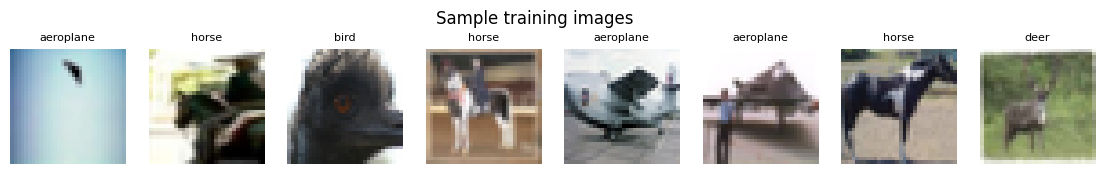

In [6]:
assert len(train_dataset) == 45000,      f"Train size is {len(train_dataset)}"
assert len(validation_dataset) == 5000,  f"Validation size is {len(validation_dataset)}"
assert len(test_dataset) == 10000,       f"Test size is {len(test_dataset)}"
assert len(set(train_indices) & set(val_indices)) == 0, "Train/validation overlap!"
assert len(train_indices) + len(val_indices) == 50000

images, labels = next(iter(train_loader))
assert images.shape == (BATCH_SIZE, 3, 32, 32), f"Unexpected batch shape {images.shape}"
assert labels.min() >= 0 and labels.max() <= 9, "Labels outside 0-9"
assert torch.isfinite(images).all(), "Non-finite pixel values"

print(f"Train / Val / Test sizes: {len(train_dataset)} / {len(validation_dataset)} / {len(test_dataset)}")
print(f"Batch shape: {tuple(images.shape)} | label dtype: {labels.dtype}")
print("Per-channel batch mean (should be near 0):", images.mean(dim=(0, 2, 3)).numpy().round(3))
print("Per-channel batch std  (should be near 1):", images.std(dim=(0, 2, 3)).numpy().round(3))
print("All sanity checks passed.")

mean_t = torch.tensor(CIFAR_MEAN).view(3, 1, 1)
std_t  = torch.tensor(CIFAR_STD).view(3, 1, 1)
fig, axes = plt.subplots(1, 8, figsize=(14, 2))
for ax, img, lbl in zip(axes, images[:8], labels[:8]):
    ax.imshow((img * std_t + mean_t).clamp(0, 1).permute(1, 2, 0))
    ax.set_title(CLASS_NAMES[lbl], fontsize=8)
    ax.axis("off")
plt.suptitle("Sample training images")
plt.show()

# 6.Baseline CNN Architecture

In [7]:
class BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()

        # Trainable Layer 1
        self.conv1 = nn.Conv2d(
            in_channels=3,
            out_channels=32,
            kernel_size=3,
            padding=1
        )

        # Trainable Layer 2
        self.conv2 = nn.Conv2d(
            in_channels=32,
            out_channels=64,
            kernel_size=3,
            padding=1
        )

        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(kernel_size=2)
        self.flatten = nn.Flatten()

        # Trainable Layer 3
        self.fc = nn.Linear(64 * 8 * 8, 10)

    def forward(self, x):

        # First convolution block
        x = self.conv1(x)
        x = self.relu(x)
        x = self.pool(x)

        # Second convolution block
        x = self.conv2(x)
        x = self.relu(x)
        x = self.pool(x)

        x = self.flatten(x)

        # Classification layer
        x = self.fc(x)

        return x

# Experimental Design

The baseline CNN, as defined in Exercise 2, is the reference model. The following two experiments are run separately:
1. Dropout: a dropout layer is added to the baseline CNN to reduce overfitting by randomly deactivating features during training.
2. Data augmentation: random transformations are applied to the training images to increase data variability.

All experiments use the same CIFAR-10 split, batch size, optimiser, learning rate, weight decay and number of epochs. The baseline is retrained in this notebook with the same training function, so all models are compared on the same hardware and measured with the same protocol.

# 7.Evaluation Function

In [8]:
def evaluate_model(model, data_loader, criterion):

    model.eval()

    total_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    with torch.no_grad():

        for images, labels in data_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            batch_size = labels.size(0)

            total_loss += loss.item() * batch_size

            predictions = outputs.argmax(dim=1)

            correct_predictions += (predictions == labels).sum().item()

            total_samples += batch_size

    average_loss = total_loss / total_samples

    accuracy = (correct_predictions / total_samples) * 100

    return average_loss, accuracy

# 8.Training Function

Every model in this exercise is trained from scratch with the same training configuration.

*   Optimizer: Adam
*   Learning rate: 0.001
*   Weight decay: 0.0
*   Batch size: 128
*   Number of epochs: 20
*   Loss function: Cross-Entropy Loss

After every epoch, the model is evaluated on the training and validation sets. Only the checkpoint with the highest validation accuracy is kept. After training, that checkpoint is restored and evaluated once on the official test set.

In [9]:
def train_model(
    model,
    train_loader,
    train_eval_loader,
    validation_loader,
    epochs=EPOCHS
):

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "validation_loss": [],
        "validation_accuracy": []
    }

    best_validation_accuracy = -1.0
    best_epoch = 0
    best_model_state = None

    start_time = time.perf_counter()

    for epoch in range(epochs):

        model.train()

        running_loss = 0.0
        correct_predictions = 0
        total_samples = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad(set_to_none=True)

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            batch_size = labels.size(0)

            running_loss += loss.item() * batch_size

            predictions = outputs.argmax(dim=1)

            correct_predictions += (predictions == labels).sum().item()

            total_samples += batch_size

        epoch_train_loss = running_loss / total_samples

        epoch_train_accuracy = (
            correct_predictions / total_samples
        ) * 100

        # evaluate training and validation performance
        train_eval_loss, train_eval_accuracy = evaluate_model(
            model,
            train_eval_loader,
            criterion
        )

        validation_loss, validation_accuracy = evaluate_model(
            model,
            validation_loader,
            criterion
        )

        history["train_loss"].append(train_eval_loss)
        history["train_accuracy"].append(train_eval_accuracy)
        history["validation_loss"].append(validation_loss)
        history["validation_accuracy"].append(validation_accuracy)

        # select the best checkpoint using validation accuracy
        if validation_accuracy > best_validation_accuracy:

            best_validation_accuracy = validation_accuracy
            best_epoch = epoch + 1

            best_model_state = copy.deepcopy(
                model.state_dict()
            )

        print(
            f"Epoch [{epoch + 1}/{epochs}] "
            f"| Train Loss: {train_eval_loss:.4f} "
            f"| Train Acc: {train_eval_accuracy:.2f}% "
            f"| Val Loss: {validation_loss:.4f} "
            f"| Val Acc: {validation_accuracy:.2f}%"
        )

    training_time = time.perf_counter() - start_time

    # restore the best validation checkpoint
    model.load_state_dict(best_model_state)

    print("\nTraining completed.")
    print("Best epoch:", best_epoch)
    print(
        f"Best validation accuracy: "
        f"{best_validation_accuracy:.2f}%"
    )
    print(f"Training time: {training_time:.2f} seconds")

    return model, history, best_epoch, training_time

# 9.Helper Functions

Shared helpers: a freshly seeded training DataLoader, a non-shuffled loader for evaluating on the clean training set, a parameter counter, and a function that collects train, validation and test results for a trained model.

In [10]:
def make_train_loader():
    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        worker_init_fn=seed_worker,
        generator=generator,
        pin_memory=(device.type == "cuda"),
    )


train_eval_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda"),
)


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def collect_results(name, model, best_epoch, training_time):
    criterion = nn.CrossEntropyLoss()
    train_loss, train_acc = evaluate_model(model, train_eval_loader, criterion)
    val_loss, val_acc = evaluate_model(model, validation_loader, criterion)
    test_loss, test_acc = evaluate_model(model, test_loader, criterion)
    return {
        "Experiment": name,
        "Best Epoch": best_epoch,
        "Train Accuracy (%)": train_acc,
        "Validation Accuracy (%)": val_acc,
        "Test Accuracy (%)": test_acc,
        "Train Loss": train_loss,
        "Validation Loss": val_loss,
        "Test Loss": test_loss,
        "Train-Validation Gap (pp)": train_acc - val_acc,
        "Parameters": count_parameters(model),
        "Training Time (seconds)": training_time,
    }

# 10.Baseline CNN (Retrained here)

The baseline is retrained here with the same training and evaluation functions as the other experiments, so that its training accuracy, test accuracy and train test gap are directly comparable.

In [11]:
set_seed(SEED)
baseline_model = BaselineCNN().to(device)

baseline_model, baseline_history, baseline_best_epoch, baseline_training_time = train_model(
    model=baseline_model,
    train_loader=make_train_loader(),
    train_eval_loader=train_eval_loader,
    validation_loader=validation_loader,
    epochs=EPOCHS,
)

baseline_results = collect_results(
    "Baseline CNN", baseline_model, baseline_best_epoch, baseline_training_time
)
torch.save(baseline_model.state_dict(), "cnn_baseline_best_validation_ex3.pth")
display(pd.DataFrame([baseline_results]))

assert baseline_results["Parameters"] == 60362
assert len(baseline_history["train_loss"]) == EPOCHS
assert baseline_best_epoch == int(np.argmax(baseline_history["validation_accuracy"])) + 1
assert abs(baseline_results["Validation Accuracy (%)"]
           - baseline_history["validation_accuracy"][baseline_best_epoch - 1]) < 0.05

print(f"Exercise 2 reference: test 70.72% | this run: {baseline_results['Test Accuracy (%)']:.2f}%")
print("Baseline retraining tests passed.")

Epoch [1/20] | Train Loss: 1.0899 | Train Acc: 62.22% | Val Loss: 1.1274 | Val Acc: 60.30%
Epoch [2/20] | Train Loss: 0.9408 | Train Acc: 67.94% | Val Loss: 1.0189 | Val Acc: 65.54%
Epoch [3/20] | Train Loss: 0.8144 | Train Acc: 72.22% | Val Loss: 0.9281 | Val Acc: 68.24%
Epoch [4/20] | Train Loss: 0.7364 | Train Acc: 74.86% | Val Loss: 0.8859 | Val Acc: 69.50%
Epoch [5/20] | Train Loss: 0.6797 | Train Acc: 76.67% | Val Loss: 0.8639 | Val Acc: 70.52%
Epoch [6/20] | Train Loss: 0.6169 | Train Acc: 79.21% | Val Loss: 0.8442 | Val Acc: 71.80%
Epoch [7/20] | Train Loss: 0.5725 | Train Acc: 80.96% | Val Loss: 0.8353 | Val Acc: 72.42%
Epoch [8/20] | Train Loss: 0.5497 | Train Acc: 81.16% | Val Loss: 0.8701 | Val Acc: 71.14%
Epoch [9/20] | Train Loss: 0.4936 | Train Acc: 83.55% | Val Loss: 0.8419 | Val Acc: 72.38%
Epoch [10/20] | Train Loss: 0.4934 | Train Acc: 83.08% | Val Loss: 0.8881 | Val Acc: 71.30%
Epoch [11/20] | Train Loss: 0.4374 | Train Acc: 85.31% | Val Loss: 0.8758 | Val Acc: 71.7

,Experiment,Best Epoch,Train Accuracy (%),Validation Accuracy (%),Test Accuracy (%),Train Loss,Validation Loss,Test Loss,Train-Validation Gap (pp),Parameters,Training Time (seconds)
0,Baseline CNN,7,80.96,72.42,71.31,0.572539,0.835308,0.855838,8.54,60362,497.4008


Exercise 2 reference: test 70.72% | this run: 71.31%
Baseline retraining tests passed.


---

# Dropout Experiment

In this experiment, dropout with probability 0.3 is placed between the flatten layer and the fully connected classifier.

- The classifier receives 4,096 features and holds 40,970 of the 60,362 trainable parameters (about 68%), so this is where most of the overfitting capacity sits.
- Dropout adds no trainable parameters, so the model size stays at 60,362.
- p = 0.3 is a moderate rate chosen before training and not tuned on the test set.
- About 30% of the flattened features are randomly deactivated at each training step. Dropout is switched off automatically during validation and test evaluation.

**Dropout CNN Architecture**

The dropout model follows the same architecture as the baseline CNN, with one additional dropout layer.


*   Two convolutional layers.
*   ReLU activation functions.
*   Two max-pooling operations.
*   A flattening operation.
*   A dropout layer with a probability of 0.3.
*   A fully connected output layer with 10 neurons.

The dropout layer does not introduce additional trainable parameters. Therefore, the total number of trainable parameters remains the same as the baseline CNN.

# 1.Creating the dropout model

In [12]:
class DropoutCNN(nn.Module):
    def __init__(self, dropout_probability=0.3):
        super().__init__()

        # First convolutional layer
        self.conv1 = nn.Conv2d(
            in_channels=3,
            out_channels=32,
            kernel_size=3,
            padding=1
        )

        # Second convolutional layer
        self.conv2 = nn.Conv2d(
            in_channels=32,
            out_channels=64,
            kernel_size=3,
            padding=1
        )

        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(kernel_size=2)
        self.flatten = nn.Flatten()

        # Dropout layer
        self.dropout = nn.Dropout(p=dropout_probability)

        # Fully connected classification layer
        self.fc = nn.Linear(64 * 8 * 8, 10)

    def forward(self, x):

        # First convolution block
        x = self.conv1(x)
        x = self.relu(x)
        x = self.pool(x)

        # Second convolution block
        x = self.conv2(x)
        x = self.relu(x)
        x = self.pool(x)

        x = self.flatten(x)

        # Apply dropout
        x = self.dropout(x)

        # Classification layer
        x = self.fc(x)

        return x

# 2.Checking the architecture and parameter count

In [13]:
set_seed(SEED)

dropout_model = DropoutCNN(dropout_probability=0.3).to(device)

print(dropout_model)

dropout_parameters = sum(
    p.numel()
    for p in dropout_model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", dropout_parameters)

assert dropout_parameters == 60362, \
    "Unexpected number of trainable parameters!"

print("Dropout CNN architecture checks passed!")

DropoutCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=4096, out_features=10, bias=True)
)
Trainable parameters: 60362
Dropout CNN architecture checks passed!


**Pre-training tests**

These checks verify the data split, the architecture, the dropout behaviour, and that dropout is the only difference from the baseline.

In [14]:
EXPECTED_SPLIT_HASH = "d45cf7fe22a123b42b27274bddc38a8e"

assert split_hash == EXPECTED_SPLIT_HASH
assert len(train_dataset) == 45000
assert len(validation_dataset) == 5000
assert len(test_dataset) == 10000
assert not any("Random" in type(t).__name__ for t in train_transform.transforms)

set_seed(SEED)
baseline_check = BaselineCNN().to(device)
set_seed(SEED)
dropout_check = DropoutCNN(dropout_probability=0.3).to(device)

assert count_parameters(baseline_check) == 60362
assert count_parameters(dropout_check) == 60362
assert all(
    torch.equal(a, b)
    for a, b in zip(baseline_check.state_dict().values(), dropout_check.state_dict().values())
)

baseline_layers = [type(m).__name__ for m in baseline_check.children()]
dropout_layers = [type(m).__name__ for m in dropout_check.children() if not isinstance(m, nn.Dropout)]
assert baseline_layers == dropout_layers

call_order = []
hooks = [
    m.register_forward_hook(lambda module, inputs, output, n=name: call_order.append(n))
    for name, m in dropout_check.named_children()
]
dropout_check.eval()
dropout_check(torch.zeros(1, 3, 32, 32, device=device))
for h in hooks:
    h.remove()
assert call_order.index("dropout") == call_order.index("flatten") + 1
assert call_order.index("fc") == call_order.index("dropout") + 1

p = 0.3
layer = nn.Dropout(p=p).train()
x = torch.ones(1_000_000)
y = layer(x)
assert abs((y == 0).float().mean().item() - p) < 0.01
kept = y[y != 0]
assert torch.allclose(kept, torch.full_like(kept, 1 / (1 - p)))
layer.eval()
assert torch.equal(layer(x), x)

sample = torch.randn(8, 3, 32, 32, device=device)
dropout_check.train()
assert not torch.equal(dropout_check(sample), dropout_check(sample))
dropout_check.eval()
assert torch.equal(dropout_check(sample), dropout_check(sample))

zero_p_model = DropoutCNN(dropout_probability=0.0).to(device)
zero_p_model.load_state_dict(baseline_check.state_dict())
zero_p_model.train()
baseline_check.train()
assert torch.allclose(zero_p_model(sample), baseline_check(sample))

del baseline_check, dropout_check, zero_p_model
print("All pre-training tests passed.")

All pre-training tests passed.


# 3.Training the Dropout Model

In [15]:
set_seed(SEED)
dropout_model = DropoutCNN(dropout_probability=0.3).to(device)

dropout_model, dropout_history, dropout_best_epoch, dropout_training_time = train_model(
    model=dropout_model,
    train_loader=make_train_loader(),
    train_eval_loader=train_eval_loader,
    validation_loader=validation_loader,
    epochs=EPOCHS,
)

Epoch [1/20] | Train Loss: 1.1304 | Train Acc: 60.56% | Val Loss: 1.1612 | Val Acc: 59.02%
Epoch [2/20] | Train Loss: 0.9749 | Train Acc: 66.76% | Val Loss: 1.0325 | Val Acc: 65.40%
Epoch [3/20] | Train Loss: 0.8536 | Train Acc: 70.59% | Val Loss: 0.9387 | Val Acc: 67.64%
Epoch [4/20] | Train Loss: 0.7822 | Train Acc: 73.58% | Val Loss: 0.8884 | Val Acc: 69.52%
Epoch [5/20] | Train Loss: 0.7538 | Train Acc: 73.90% | Val Loss: 0.8763 | Val Acc: 69.84%
Epoch [6/20] | Train Loss: 0.6872 | Train Acc: 76.68% | Val Loss: 0.8368 | Val Acc: 71.06%
Epoch [7/20] | Train Loss: 0.6648 | Train Acc: 77.71% | Val Loss: 0.8293 | Val Acc: 71.46%
Epoch [8/20] | Train Loss: 0.6408 | Train Acc: 78.06% | Val Loss: 0.8346 | Val Acc: 71.54%
Epoch [9/20] | Train Loss: 0.6038 | Train Acc: 80.26% | Val Loss: 0.7980 | Val Acc: 72.76%
Epoch [10/20] | Train Loss: 0.5838 | Train Acc: 80.30% | Val Loss: 0.8000 | Val Acc: 72.66%
Epoch [11/20] | Train Loss: 0.5456 | Train Acc: 81.87% | Val Loss: 0.7801 | Val Acc: 73.6

# 4.Evaluating the Best Dropout Model

In [17]:
dropout_results = collect_results("Dropout (p=0.3)", dropout_model, dropout_best_epoch, dropout_training_time)
torch.save(dropout_model.state_dict(), "cnn_dropout_best_validation.pth")
dropout_df = pd.DataFrame([dropout_results])
display(dropout_df)
dropout_df.to_csv("dropout_results.csv", index=False)

criterion = nn.CrossEntropyLoss()

assert len(dropout_history["train_loss"]) == EPOCHS
assert all(np.isfinite(dropout_history["train_loss"] + dropout_history["validation_loss"]))
assert dropout_best_epoch == int(np.argmax(dropout_history["validation_accuracy"])) + 1
assert abs(dropout_results["Validation Accuracy (%)"]
           - dropout_history["validation_accuracy"][dropout_best_epoch - 1]) < 0.05
assert 0 <= dropout_results["Test Accuracy (%)"] <= 100
assert dropout_results["Parameters"] == baseline_results["Parameters"] == 60362
assert not dropout_model.training

_, repeat_val_acc = evaluate_model(dropout_model, validation_loader, criterion)
assert abs(repeat_val_acc - dropout_results["Validation Accuracy (%)"]) < 1e-6

reloaded_model = DropoutCNN(dropout_probability=0.3).to(device)
reloaded_model.load_state_dict(
    torch.load("cnn_dropout_best_validation.pth", map_location=device, weights_only=True)
)
_, reloaded_val_acc = evaluate_model(reloaded_model, validation_loader, criterion)
assert abs(reloaded_val_acc - dropout_results["Validation Accuracy (%)"]) < 1e-6

print("Post training tests passed.")

,Experiment,Best Epoch,Train Accuracy (%),Validation Accuracy (%),Test Accuracy (%),Train Loss,Validation Loss,Test Loss,Train-Validation Gap (pp),Parameters,Training Time (seconds)
0,Dropout (p=0.3),16,84.697778,75.08,74.33,0.467105,0.755896,0.774094,9.617778,60362,485.29514


Post training tests passed.


# 5.Visualizing Dropout Training Performance

**Loss plot**

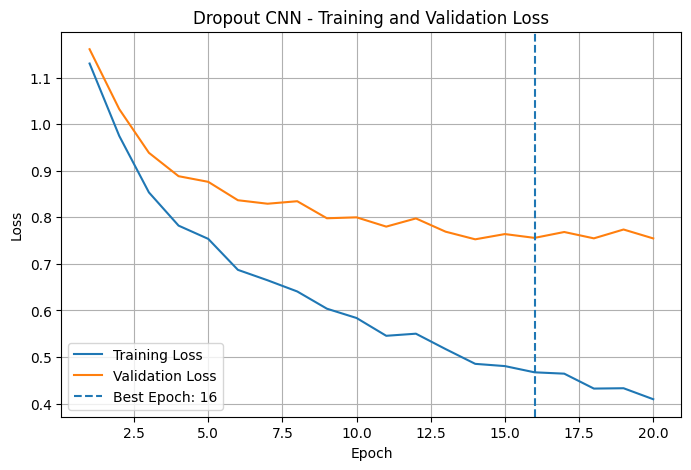

In [18]:
epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    dropout_history["train_loss"],
    label="Training Loss"
)

plt.plot(
    epochs_range,
    dropout_history["validation_loss"],
    label="Validation Loss"
)

plt.axvline(
    dropout_best_epoch,
    linestyle="--",
    label=f"Best Epoch: {dropout_best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Dropout CNN - Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.savefig(
    "dropout_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Accuracy plot**

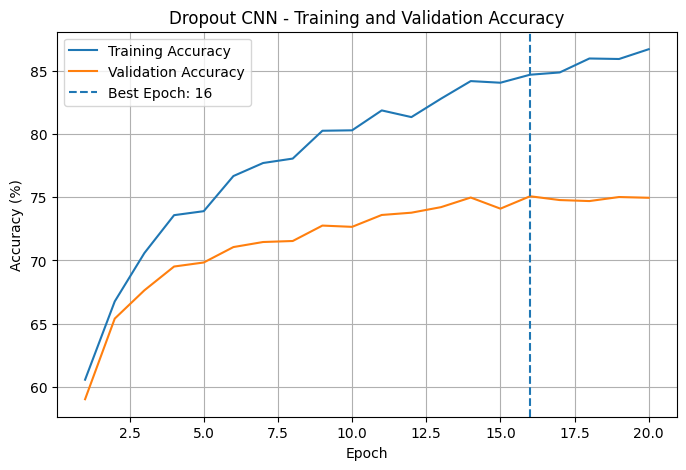

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    dropout_history["train_accuracy"],
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    dropout_history["validation_accuracy"],
    label="Validation Accuracy"
)

plt.axvline(
    dropout_best_epoch,
    linestyle="--",
    label=f"Best Epoch: {dropout_best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Dropout CNN - Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.savefig(
    "dropout_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Baseline vs dropout curves**

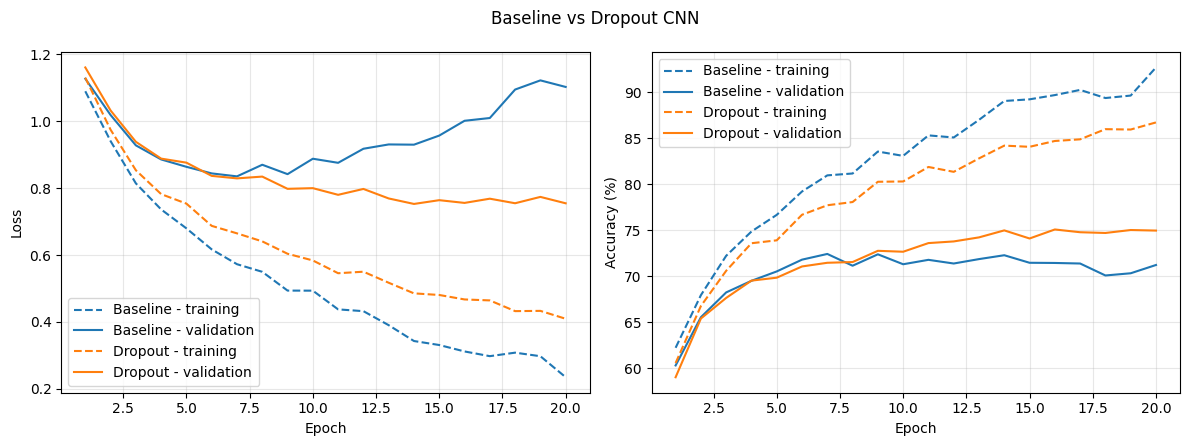

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, key, ylabel in [(axes[0], "loss", "Loss"), (axes[1], "accuracy", "Accuracy (%)")]:
    ax.plot(epochs_range, baseline_history[f"train_{key}"], "--", color="tab:blue", label="Baseline - training")
    ax.plot(epochs_range, baseline_history[f"validation_{key}"], color="tab:blue", label="Baseline - validation")
    ax.plot(epochs_range, dropout_history[f"train_{key}"], "--", color="tab:orange", label="Dropout - training")
    ax.plot(epochs_range, dropout_history[f"validation_{key}"], color="tab:orange", label="Dropout - validation")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)
    ax.legend()
fig.suptitle("Baseline vs Dropout CNN")
plt.tight_layout()
plt.savefig("baseline_vs_dropout_curves.png", dpi=300, bbox_inches="tight")
plt.show()

# Dropout Experiment Results

The dropout experiment was conducted using a dropout probability of 0.3.

The model was trained for 20 epochs, and the checkpoint with the highest validation accuracy was selected.

The final training, validation, and test metrics are presented below. These results will be compared with the baseline CNN to evaluate whether dropout improved generalization performance.

In [21]:
d = dropout_results

print("DROPOUT EXPERIMENT SUMMARY")
print("-" * 40)
print(f"Best epoch: {d['Best Epoch']}")
print(f"Training accuracy: {d['Train Accuracy (%)']:.2f}%")
print(f"Validation accuracy: {d['Validation Accuracy (%)']:.2f}%")
print(f"Test accuracy: {d['Test Accuracy (%)']:.2f}%")
print(f"Training loss: {d['Train Loss']:.4f}")
print(f"Validation loss: {d['Validation Loss']:.4f}")
print(f"Test loss: {d['Test Loss']:.4f}")
print(f"Train-validation gap: {d['Train-Validation Gap (pp)']:.2f} pp")
print(f"Train-test gap: {d['Train Accuracy (%)'] - d['Test Accuracy (%)']:.2f} pp")
print(f"Trainable parameters: {d['Parameters']}")
print(f"Training time: {d['Training Time (seconds)']:.2f} seconds ({device.type})")

DROPOUT EXPERIMENT SUMMARY
----------------------------------------
Best epoch: 16
Training accuracy: 84.70%
Validation accuracy: 75.08%
Test accuracy: 74.33%
Training loss: 0.4671
Validation loss: 0.7559
Test loss: 0.7741
Train-validation gap: 9.62 pp
Train-test gap: 10.37 pp
Trainable parameters: 60362
Training time: 485.30 seconds (cuda)


**Dropout vs baseline: key differences**

In [22]:
b, d = baseline_results, dropout_results

print("DROPOUT vs BASELINE (dropout minus baseline)")
print("-" * 55)
print(f"Training accuracy change:   {d['Train Accuracy (%)'] - b['Train Accuracy (%)']:+.2f} pp")
print(f"Validation accuracy change: {d['Validation Accuracy (%)'] - b['Validation Accuracy (%)']:+.2f} pp")
print(f"Test accuracy change:       {d['Test Accuracy (%)'] - b['Test Accuracy (%)']:+.2f} pp")
print(f"Train-test gap:             {b['Train Accuracy (%)'] - b['Test Accuracy (%)']:.2f} pp -> "
      f"{d['Train Accuracy (%)'] - d['Test Accuracy (%)']:.2f} pp")
print(f"Test loss:                  {b['Test Loss']:.4f} -> {d['Test Loss']:.4f}")
print(f"Best epoch:                 {b['Best Epoch']} -> {d['Best Epoch']}")
print(f"Epoch of lowest val loss:   {int(np.argmin(baseline_history['validation_loss'])) + 1} -> "
      f"{int(np.argmin(dropout_history['validation_loss'])) + 1}")
print(f"Final-epoch val loss:       {baseline_history['validation_loss'][-1]:.4f} -> "
      f"{dropout_history['validation_loss'][-1]:.4f}")
print(f"Final-epoch train-val gap:  "
      f"{baseline_history['train_accuracy'][-1] - baseline_history['validation_accuracy'][-1]:.2f} pp -> "
      f"{dropout_history['train_accuracy'][-1] - dropout_history['validation_accuracy'][-1]:.2f} pp")

DROPOUT vs BASELINE (dropout minus baseline)
-------------------------------------------------------
Training accuracy change:   +3.74 pp
Validation accuracy change: +2.66 pp
Test accuracy change:       +3.02 pp
Train-test gap:             9.65 pp -> 10.37 pp
Test loss:                  0.8558 -> 0.7741
Best epoch:                 7 -> 16
Epoch of lowest val loss:   7 -> 14
Final-epoch val loss:       1.1028 -> 0.7547
Final-epoch train-val gap:  21.47 pp -> 11.76 pp


---

# Data Augmentation Experiment

In this experiment, data augmentation is applied to the training images only, while the baseline CNN architecture is kept exactly the same.

Two random transformations are applied to each training image every time it is loaded: a random crop with 4 pixels of padding, which shifts the object slightly, and a random horizontal flip with a probability of 0.5, which mirrors the image left to right. This means the model sees a slightly different version of each image in every epoch.

Validation and test images are not augmented. Other architectural and training parameters have been kept the same as the base model in order to study the impact of data augmentation independently.

**Data Augmentation Setup**

The augmentation model uses the same architecture as the baseline CNN, with no changes to the layers.

*   Two convolutional layers (32 and 64 channels).
*   ReLU activation functions.
*   Two max-pooling operations.
*   A flattening operation.
*   A fully connected output layer with 10 neurons.
*   Training transform: RandomCrop(32, padding=4) and RandomHorizontalFlip(p=0.5), applied before ToTensor() and normalisation.

These transformations keep the CIFAR-10 labels correct, because a shifted or mirrored car is still a car. Vertical flips and large rotations were not used because they create unrealistic images, such as upside-down ships.

Data augmentation does not add any trainable parameters. Therefore, the total number of trainable parameters remains the same as the baseline CNN (60,362). Training accuracy and loss are measured on the non-augmented training images so that they can be compared directly with the baseline and dropout results.

# 1.Creating the augmented training dataset

In [ ]:
augment_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD)
])

full_train_augmented = datasets.CIFAR10(
    DATA_DIR,
    train=True,
    download=True,
    transform=augment_transform
)

augmented_train_dataset = Subset(
    full_train_augmented,
    train_indices.tolist()
)

# Split checks
assert len(augmented_train_dataset) == 45000, "Augmented training set must contain 45,000 images"
assert augmented_train_dataset.indices == train_dataset.indices, "Training indices differ from the baseline split!"
assert hashlib.md5(val_indices.tobytes()).hexdigest() == split_hash, "Validation split has changed!"
assert len(set(augmented_train_dataset.indices) & set(val_indices.tolist())) == 0, "Train/validation overlap!"

print("Augmented training images:", len(augmented_train_dataset))
print("Validation images (unchanged, no augmentation):", len(validation_dataset))
print("Test images (unchanged, no augmentation):", len(test_dataset))
print(f"Validation-index fingerprint (md5): {split_hash}")
print("Augmented dataset uses the same split as the baseline.")

# 2.Visualising the augmentation

In [ ]:
set_seed(SEED)

mean_t = torch.tensor(CIFAR_MEAN).view(3, 1, 1)
std_t  = torch.tensor(CIFAR_STD).view(3, 1, 1)

def denormalise(img):
    return (img * std_t + mean_t).clamp(0, 1).permute(1, 2, 0)

sample_positions = range(6)
fig, axes = plt.subplots(3, 6, figsize=(12, 6))

for col, pos in enumerate(sample_positions):
    original_img, label = train_dataset[pos]
    axes[0, col].imshow(denormalise(original_img))
    axes[0, col].set_title(CLASS_NAMES[label], fontsize=9)
    for row in (1, 2):
        aug_img, _ = augmented_train_dataset[pos]
        axes[row, col].imshow(denormalise(aug_img))

for ax in axes.flat:
    ax.axis("off")

axes[0, 0].text(-12, 16, "Original", rotation=90, va="center", fontsize=9)
axes[1, 0].text(-12, 16, "Augmented", rotation=90, va="center", fontsize=9)
axes[2, 0].text(-12, 16, "Augmented", rotation=90, va="center", fontsize=9)

plt.suptitle("Original vs augmented training images (random crop + horizontal flip)")
plt.tight_layout()
plt.savefig("augmentation_examples.png", dpi=300, bbox_inches="tight")
plt.show()

# 3.Augmentation DataLoaders

In [ ]:
set_seed(SEED)

augmentation_generator = torch.Generator().manual_seed(SEED)

augmentation_train_loader = DataLoader(
    augmented_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    worker_init_fn=seed_worker,
    generator=augmentation_generator,
    pin_memory=(device.type == "cuda")
)

augmentation_train_eval_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

aug_images, aug_labels = next(iter(augmentation_train_loader))
assert aug_images.shape == (BATCH_SIZE, 3, 32, 32), f"Unexpected batch shape {aug_images.shape}"
assert torch.isfinite(aug_images).all(), "Non-finite pixel values"

print("Augmented batch shape:", tuple(aug_images.shape))
print("Augmentation DataLoaders created.")

# 4.Training the baseline CNN with augmented data

A fresh, unchanged `BaselineCNN` is trained from scratch using the same training function and configuration as the dropout experiment (Adam, learning rate 0.001, weight decay 0.0, batch size 128, 20 epochs, cross-entropy loss). The checkpoint with the highest validation accuracy is restored after training.

In [ ]:
set_seed(SEED)

augmentation_model = BaselineCNN().to(device)

augmentation_parameters = sum(
    p.numel()
    for p in augmentation_model.parameters()
    if p.requires_grad
)

print(augmentation_model)
print("Trainable parameters:", augmentation_parameters)

assert augmentation_parameters == 60362, "Architecture differs from the baseline CNN!"

augmentation_model, augmentation_history, augmentation_best_epoch, augmentation_training_time = train_model(
    model=augmentation_model,
    train_loader=augmentation_train_loader,
    train_eval_loader=augmentation_train_eval_loader,
    validation_loader=validation_loader,
    epochs=EPOCHS
)

# 5.Evaluating the best augmentation model

In [ ]:
criterion = nn.CrossEntropyLoss()

aug_train_loss, aug_train_accuracy = evaluate_model(
    augmentation_model,
    augmentation_train_eval_loader,
    criterion
)

aug_val_loss, aug_val_accuracy = evaluate_model(
    augmentation_model,
    validation_loader,
    criterion
)

aug_test_loss, aug_test_accuracy = evaluate_model(
    augmentation_model,
    test_loader,
    criterion
)

aug_accuracy_gap = aug_train_accuracy - aug_val_accuracy

augmentation_results = {
    "Experiment": "Data Augmentation (crop + flip)",
    "Best Epoch": augmentation_best_epoch,
    "Train Accuracy (%)": aug_train_accuracy,
    "Validation Accuracy (%)": aug_val_accuracy,
    "Test Accuracy (%)": aug_test_accuracy,
    "Train Loss": aug_train_loss,
    "Validation Loss": aug_val_loss,
    "Test Loss": aug_test_loss,
    "Accuracy Gap (%)": aug_accuracy_gap,
    "Parameters": augmentation_parameters,
    "Training Time (seconds)": augmentation_training_time
}

augmentation_df = pd.DataFrame([augmentation_results])
display(augmentation_df)

torch.save(
    augmentation_model.state_dict(),
    "cnn_augmentation_best_validation.pth"
)

print("\nBest augmentation checkpoint saved.")

# 6.Visualising augmentation training performance

In [ ]:
epochs_range = range(1, EPOCHS + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss
axes[0].plot(epochs_range, augmentation_history["train_loss"], label="Training Loss")
axes[0].plot(epochs_range, augmentation_history["validation_loss"], label="Validation Loss")
axes[0].axvline(augmentation_best_epoch, linestyle="--", color="grey",
                label=f"Best Epoch: {augmentation_best_epoch}")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Augmentation CNN - Training and Validation Loss")
axes[0].legend()
axes[0].grid(True)

# Accuracy
axes[1].plot(epochs_range, augmentation_history["train_accuracy"], label="Training Accuracy")
axes[1].plot(epochs_range, augmentation_history["validation_accuracy"], label="Validation Accuracy")
axes[1].axvline(augmentation_best_epoch, linestyle="--", color="grey",
                label=f"Best Epoch: {augmentation_best_epoch}")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_title("Augmentation CNN - Training and Validation Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("augmentation_loss_accuracy.png", dpi=300, bbox_inches="tight")
plt.show()

# Data Augmentation Experiment Results

The model was trained for 20 epochs and the checkpoint with the highest validation accuracy was selected. Training accuracy and loss are measured on the non-augmented training images.

In [ ]:
print("DATA AUGMENTATION EXPERIMENT SUMMARY")
print("-" * 40)

print(f"Best epoch: {augmentation_best_epoch}")
print(f"Training accuracy: {aug_train_accuracy:.2f}%")
print(f"Validation accuracy: {aug_val_accuracy:.2f}%")
print(f"Test accuracy: {aug_test_accuracy:.2f}%")

print(f"Training loss: {aug_train_loss:.4f}")
print(f"Validation loss: {aug_val_loss:.4f}")
print(f"Test loss: {aug_test_loss:.4f}")

print(f"Accuracy gap (train - validation): {aug_accuracy_gap:.2f} percentage points")
print(f"Accuracy gap (train - test): {aug_train_accuracy - aug_test_accuracy:.2f} percentage points")
print(f"Trainable parameters: {augmentation_parameters}")
print(f"Training time: {augmentation_training_time:.2f} seconds")

# Baseline vs Dropout vs Augmentation Comparison

All three models (baseline, dropout and augmentation) were retrained in this notebook with the same training function, split and settings. Each technique is evaluated independently against the unchanged baseline. The **train–test gap** (training accuracy − test accuracy, in percentage points) is the generalisation measure used for Exercise 3.

In [ ]:
comparison_rows = []
for change, result in [
    ("None", baseline_results),
    ("Dropout only", dropout_results),
    ("Training transforms only", augmentation_results),
]:
    comparison_rows.append({
        "Condition": result["Experiment"],
        "Change from baseline": change,
        "Best Epoch": result["Best Epoch"],
        "Train Accuracy (%)": round(result["Train Accuracy (%)"], 2),
        "Validation Accuracy (%)": round(result["Validation Accuracy (%)"], 2),
        "Test Accuracy (%)": round(result["Test Accuracy (%)"], 2),
        "Train-Test Gap (pp)": round(result["Train Accuracy (%)"] - result["Test Accuracy (%)"], 2),
        "Train-Validation Gap (pp)": round(result["Train Accuracy (%)"] - result["Validation Accuracy (%)"], 2),
        "Test Loss": round(result["Test Loss"], 4),
        "Parameters": result["Parameters"],
    })

exercise3_comparison_df = pd.DataFrame(comparison_rows)
display(exercise3_comparison_df)
exercise3_comparison_df.to_csv("exercise3_results.csv", index=False)
print("Saved exercise3_results.csv")

In [ ]:
labels = ["Baseline", "Dropout (p=0.3)", "Augmentation"]
metrics = ["Train Accuracy (%)", "Validation Accuracy (%)", "Test Accuracy (%)"]
x = np.arange(len(labels))
bar_width = 0.25

fig, ax = plt.subplots(figsize=(9, 5))
for i, metric in enumerate(metrics):
    values = exercise3_comparison_df[metric].values
    bars = ax.bar(x + (i - 1) * bar_width, values, bar_width, label=metric.replace(" (%)", ""))
    ax.bar_label(bars, fmt="%.1f", fontsize=8, padding=2)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 100)
ax.set_title("Exercise 3 - Baseline vs Dropout vs Data Augmentation")
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("exercise3_accuracy_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
base = exercise3_comparison_df.iloc[0]
aug  = exercise3_comparison_df.iloc[2]

print("AUGMENTATION vs BASELINE (augmentation minus baseline)")
print("-" * 55)
print(f"Training accuracy change:   {aug['Train Accuracy (%)'] - base['Train Accuracy (%)']:+.2f} pp")
print(f"Validation accuracy change: {aug['Validation Accuracy (%)'] - base['Validation Accuracy (%)']:+.2f} pp")
print(f"Test accuracy change:       {aug['Test Accuracy (%)'] - base['Test Accuracy (%)']:+.2f} pp")
print(f"Train-test gap:             {base['Train-Test Gap (pp)']:.2f} pp -> {aug['Train-Test Gap (pp)']:.2f} pp")
print(f"Test loss:                  {base['Test Loss']:.4f} -> {aug['Test Loss']:.4f}")

**Discussion of data augmentation**

Data augmentation does not change the model: the parameter count stays at 60,362. Instead, it changes what the model sees during training. Because every epoch shows a slightly different shifted or mirrored version of each image, the network cannot simply memorise the exact pixels of the 45,000 training images and has to learn features that still work when the object moves or is flipped. This makes the training task harder, so training accuracy is expected to rise more slowly, while the features learned should transfer better to unseen validation and test images.

The measured changes in training accuracy, test accuracy and the train–test gap are shown in the comparison above. These conclusions come from a single run with seed 42, so small differences should be interpreted with caution.

# Overall Discussion: Dropout vs Data Augmentation

**Which technique improved generalisation?** Dropout changed the train–test gap from ___ pp to ___ pp and test accuracy by ___ pp. Data augmentation changed the gap from ___ pp to ___ pp and test accuracy by ___ pp.

**Which had limited benefit, and why?** ___ (compare the two techniques using the table above; mention that dropout adds noise to features but leaves the training images unchanged, while augmentation enlarges the effective training set).

**Training behaviour.** Training accuracy fell from ___ % (baseline) to ___ % (dropout) and ___ % (augmentation), showing that both techniques make fitting the training data harder. The best epochs were ___ (baseline), ___ (dropout) and ___ (augmentation).

**Limitations.** Each technique was tested at a single setting (p = 0.3; crop + flip), with one seed and a fixed 20-epoch budget. Techniques whose best epoch is close to 20 may still have been improving. Combining the two techniques was not evaluated in this exercise.